# Historical Climate Analysis — Data Cleaning & EDA

**Question:** What do the observed daily temperatures and precipitation tell us about seasonal patterns in Navojoa, Sonora?

This notebook follows a data-cleaning, descriptive-statistics, visualization and interpretation workflow. It is a modernized companion to the preserved original notebook. Source: Mexican National Meteorological Service (SMN), station 26131, daily records dated 1931–1993, with unequal coverage.

**Variables:** precipitation in mm per observed day, and maximum/minimum temperatures in °C. Missing observations are not zeros.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import seaborn as sns
root = Path.cwd()
if not (root / 'ClimatologiaNavojoa.txt').exists(): root = root.parent
sys.path.insert(0, str(root / 'scripts'))
from climate_processing import load_daily, monthly_climatology, annual_summary
df = load_daily()
df.head()


,date,precip_mm,tmax_c,tmin_c,year,month
0,1931-01-01,0.0,28.0,8.0,1931,1
1,1931-01-02,0.0,29.0,7.0,1931,1
2,1931-01-03,0.0,29.0,9.0,1931,1
3,1931-01-04,0.0,29.0,6.0,1931,1
4,1931-01-05,0.0,26.0,5.0,1931,1


## 1. Data quality audit

We first inspect the number of valid observations and missing values in each variable. A missing measurement is not the same as zero rainfall. This matters because missing observations should not be included as measured values.

In [2]:
print(df[['date','precip_mm','tmax_c','tmin_c']].isna().sum())
print('Rows:',len(df),'date range:',df.date.min(),df.date.max())
df[['precip_mm','tmax_c','tmin_c']].describe()


date           0
precip_mm     34
tmax_c        82
tmin_c       111
dtype: int64
Rows: 13404 date range: 1931-01-01 00:00:00 1993-07-31 00:00:00


,precip_mm,tmax_c,tmin_c
count,13370.000000,13322.000000,13293.000000
mean,1.015999,34.195016,14.528549
std,6.192861,6.081358,7.343251
min,0.000000,11.000000,-7.000000
25%,0.000000,30.000000,9.000000
50%,0.000000,35.000000,13.000000
75%,0.000000,39.000000,21.000000
max,254.000000,52.000000,40.000000


## 2. Seasonal patterns

We group all available daily observations by calendar month. **Mean daily precipitation** describes rainfall per recorded day, not the total rain accumulated in a month. The temperature curves show means of daily maxima and minima. Month-to-month sample sizes may differ.

,month,mean_daily_precip_mm,precipitation_observations,mean_tmax_c,mean_tmin_c
0,1,0.606265,1213,27.084158,6.979373
1,2,0.443551,1132,28.838938,7.473451
2,3,0.215277,1211,31.239274,8.545301
3,4,0.011008,1181,34.236441,10.594915
4,5,0.000925,1081,36.686486,13.870270
5,6,0.383523,1141,38.966696,20.997371
6,7,2.692464,1181,38.682485,23.886109
7,8,3.696030,1083,38.185325,23.190969
8,9,2.340299,1072,38.190476,22.279048
9,10,0.809315,1095,36.548624,17.554128


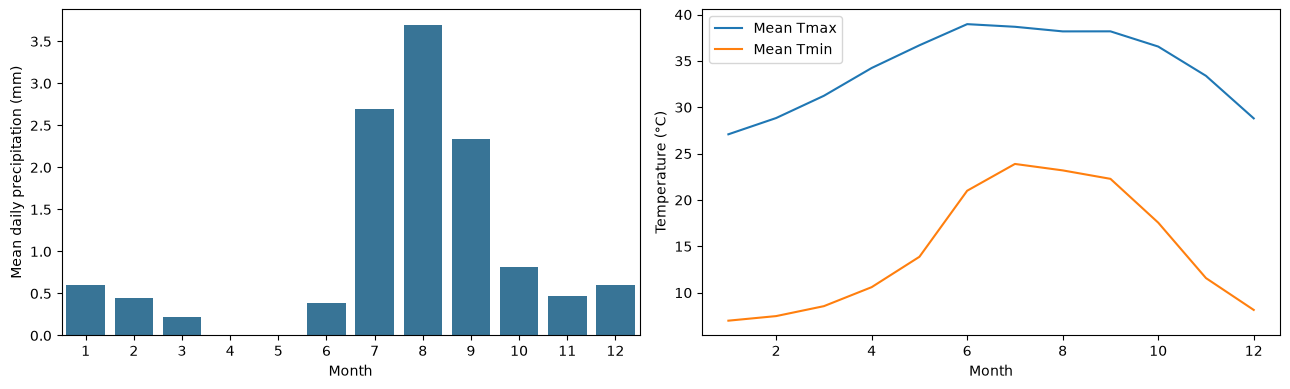

In [3]:
climate = monthly_climatology(df)
display(climate)
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.barplot(data=climate,x='month',y='mean_daily_precip_mm',ax=axes[0],color='#2878a6')
axes[0].set(ylabel='Mean daily precipitation (mm)',xlabel='Month')
axes[1].plot(climate.month,climate.mean_tmax_c,label='Mean Tmax')
axes[1].plot(climate.month,climate.mean_tmin_c,label='Mean Tmin')
axes[1].set(xlabel='Month',ylabel='Temperature (°C)')
axes[1].legend()
plt.tight_layout()
plt.show()


## 3. Temperature distributions

These histograms show how frequently different daily temperatures were observed. The optional density curve helps visualize the distribution, but it does not indicate how temperatures changed over time.

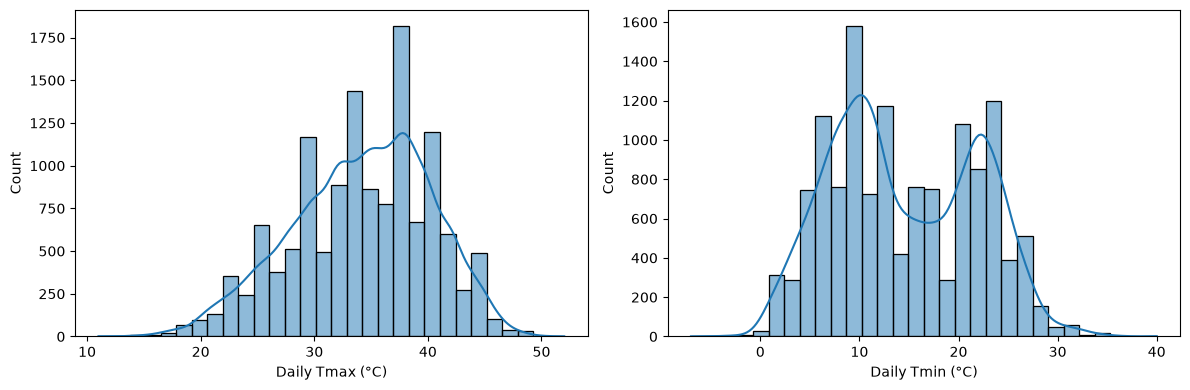

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.histplot(df.tmax_c.dropna(),bins=30,kde=True,ax=axes[0])
sns.histplot(df.tmin_c.dropna(),bins=30,kde=True,ax=axes[1])
axes[0].set(xlabel='Daily Tmax (°C)')
axes[1].set(xlabel='Daily Tmin (°C)')
plt.tight_layout()
plt.show()


## 4. Key findings and limitations

Among recorded observations, August has the highest average daily precipitation (about **3.70 mm per recorded day**). Mean recorded daily maximum temperature peaks in June (about **38.97 °C**), while mean recorded daily minimum temperature peaks in July (about **23.89 °C**).

These are **descriptive** seasonal averages from available data, not monthly precipitation totals or evidence of long-term climate change. Different months and years have different observation counts, so incomplete data can bias comparisons. Histograms represent observed distributions, not changes over time.

**Next step for scientific inference:** audit annual completeness before comparing decades or testing trends.